## Miembros del equipo

- Jorge Manuel Oyoqui Aguilera || A01711783
- Facundo Bautista Barbera || A01066843
- Oswaldo Isaías Hernández Santes || A01199004
- Alfredo Alejandro Soto Herrera || A01711368
- Emiliano Camacho Ponce || A01712408
- Iker Mejía Hernández || A01352358

## TC 3007B
### Word Embeddings

<br>

#### Activity 1: Exploring Word Embeddings with GloVe and Numpy
<br>

- Objective:
    - To understand the concept of word embeddings and their significance in Natural Language Processing.
    - To learn how to manipulate and visualize high-dimensional data using dimensionality reduction techniques like PCA and t-SNE.
    - To gain hands-on experience in implementing word similarity and analogies using GloVe embeddings and Numpy.
    
<br>

- Instructions:
    - Download GloVe pre-trained vectors from the provided link in Canvas, the official public project:
    Jeffrey Pennington, Richard Socher, and Christopher D. Manning. 2014. GloVe: Global Vectors for Word Representation
    https://nlp.stanford.edu/data/glove.6B.zip

    - Create a dictorionay of the embeddings so that you carry out fast look ups. Save that dictionary e.g. as a serialized file for faster loading in future uses.
    
    - PCA and t-SNE Visualization: After loading the GloVe embeddings, use Numpy and Sklearn to perform PCA and t-SNE to reduce the dimensionality of the embeddings and visualize them in a 2D or 3D space.

    - Word Similarity: Implement a function that takes a word as input and returns the 'n' most similar words based on their embeddings. You should use Numpy to implement this function, using libraries that already implement this function (e.g. Gensim) will result in zero points.

    - Word Analogies: Implement a function to solve analogies between words. For example, "man is to king as woman is to ____". You should use Numpy to implement this function, using libraries that already implement this function (e.g. Gensim) will result in zero points.

    - Submission: This activity is to be submitted in teams of 3 or 4. Only one person should submit the final work, with the full names of all team members included in a markdown cell at the beginning of the notebook.
    
<br>

- Evaluation Criteria:

    - Code Quality (10%): Your code should be well-organized, clearly commented, and easy to follow. Use also markdown cells for clarity.
    - Functionality (90%): All functions should work as intended, without errors.
       - Visualization of PCA and t-SNE (15% each for a total of 30%)
       - Similarity function (30%)
       - Analogy function (30%)


## 1. Fundamentos teóricos de NLP, embeddings y GloVe

Antes de empezar a realizar el código, vamos a desarrollar esta pequeña sección para dejar en claro las bases con las que vamos a estar trabajando.

### 1.1. ¿Qué es NLP?

NLP significa *Natural Language Processing*, y es una rama de la inteligencia artificial donde su objetivo es desarrollar métodos computacionales para poder procesar, interpretar y generar lenguaje humano.

El principal problema es que las computadoras no entienden las palabras de la misma forma que nosotros. Por ejemplo, nosotros entendemos que un perro o un gato son animales, que México e Italia son países, una manzana y una naranja son frutas, etc. Pero para las computadoras estas palabras son solamente cadenas de caracteres, de modo que necesitamos transformar dichas palabras en representaciones numéricas las cuales permitan hacer operaciones matemáticas.

Para eso existen los **word embeddings**, que es lo que explicaremos a continuación.

### 1.2. ¿Qué es un word embedding?

Un word embedding es la representación numérica de una palabra a través de un vector de números reales donde sus valores se aprenden de los datos de entrenamiento.

Por ejemplo, si tuviéramos un vocabulario con las siguientes 5 palabras: `['dog', 'cat', 'king', 'queen', 'apple']`, entonces podríamos usar One-Hot Encoding para representarlas de la siguiente forma:

| Palabra | One-Hot Encoding |
| --- | --- |
| dog	| [1, 0, 0, 0, 0] |
| cat |	[0, 1, 0, 0, 0] |
| king |	[0, 0, 1, 0, 0] |
| queen |	[0, 0, 0, 1, 0] |
| apple |	[0, 0, 0, 0, 1] |

Pero el problema con este método es que no permite que haya ninguna relación semántica entre las palabras. Por ejemplo, matemáticamente la palabra `dog` estaría igual de lejos de `cat` que de `apple`.

Por su parte, los embedding usan vectores densos con los valores aprendidos, lo cual les permite representar relaciones entre palabras.

La siguiente imagen da un mejor ejemplo de lo que explico.

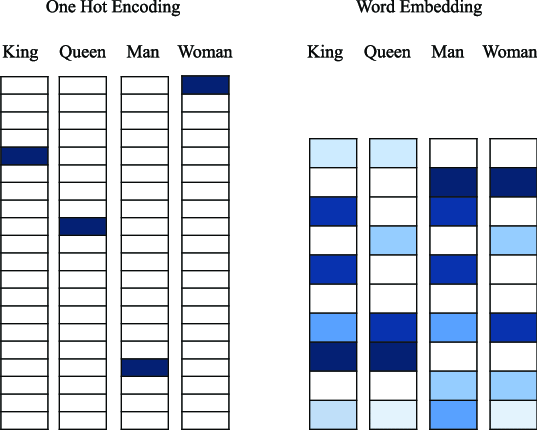

Dirección de la imagen: https://www.researchgate.net/publication/358234888/figure/fig3/AS:1128411317706759@1646045631279/Comparison-of-representations-between-one-hot-encoding-and-word-embeddings.png

Así que el objetivo es que si representamos cada palabra como un punto en un espacio vectorial, aquellas palabras que estén relacionadas estén cerca las unas de las otras.

En nuestro caso, no vamos a tener solo dos o tres dimensiones, sino 50 por cada palabra, lo cual será fundamental para representar relaciones más complejas. Aunque nos tememos que, debido al número de dimensiones, no va a ser posible visualizar de forma directa el espacio completo.

### 1.3. ¿Qué es GloVe?

GloVe significa Global Vectors for Word Representation. Es un método de aprendizaje no supervisado el cual genera embeddings a partir de las estadísticas de coocurrencia de palabras en grandes cantidades de texto. En palabras más sencillas, es estudiar que palabras suelen aparecer más cerca de otras palabras.

Por poner un ejemplo, si tenemos las siguientes oraciones:
```
The dog eats food.
The cat eats food.
The dog is an animal.
The cat is an animal.
```
Entonces tenemos que `dog` y `cat` estan en contextos parecidos, lo cual nos da evidencia estadísticas de que podría haber alguna relación entre dichas palabras.

Así que lo que hace GloVE es que utiliza esta idea pero a gran escala, donde construye estadísticas globales de coocurrencia y aprende vectores que le permitan representar esos patrones.



## 2. Importando las librerías

Empezaremos importando las librerías con las que vamos a trabajar.

- **os:** para verificar la existencia de los archivos.
- **pickle:** para guardar y recuperar el diccionario de embeddings.
- **numpy:** para manipular vectores y hacer operaciones matemáticas.
- **TSNE:** para reducir la dimensionalidad a través de t-SNE.
- **PCA:** para reducir la dimensionalidad a través de componentes principales.
- **matplotlib:** para visualizar los embeddings mediante gráficas.

In [1]:
import os
import pickle
import numpy as np
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
plt.style.use('ggplot')

## 3. Carga del archivo

Lo que hacemos con el siguiente código es descargar los embeddings de GloVe.

Es importante aclarar que para esta actividad solo vamos a extraer la versión de GloVe con 50 dimensiones.

In [2]:
# Definimos la ubicación del archivo y sus dimensiones
PATH = '/content/glove.6B.50d.txt'
emb_dim = 50
# Verificamo si es que el archivo ya existe
if not os.path.exists(PATH):
    # Si no, lo descargamos y descomprimimos
    !wget -c https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip -O /content/glove.6B.zip
    !unzip -o /content/glove.6B.zip glove.6B.50d.txt -d /content/
assert os.path.isfile(PATH), 'No se encontró el archivo GloVe'

--2026-11-25 14:33:36--  https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip
Resolving huggingface.co (huggingface.co)... 3.171.171.6, 3.171.171.104, 3.171.171.65, ...
Connecting to huggingface.co (huggingface.co)|3.171.171.6|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/621ffdc136468d709f18095d/ded22944ac944002f423d1cdb83de044851330e1a7fe19d74dc59ffa632ad294?X-Xet-Cas-Uid=public&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27glove.6B.zip%3B+filename%3D%22glove.6B.zip%22%3B&xip=Ihrc-gPi7eE&response-content-type=application%2Fzip&user_id=public&Expires=1795620816&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjIxZmZkYzEzNjQ2OGQ3MDlmMTgwOTVkL2RlZDIyOTQ0YWM5NDQwMDJmNDIzZDFjZGI4M2RlMDQ0ODUxMzMwZTFhN2ZlMTlkNzRkYzU5ZmZhNjMyYWQyOTRcXD9YLVhldC1DYXMtVWlkPXB1YmxpYyZyZXNwb25zZS1jb250ZW50LWRpc3Bvc2l0aW9uPSomeGlwPUlocmMtZ1BpN2VFJnJlc3BvbnNlLWNvbnRlbn

## 4. Creación del diccionario

Ahora, tenemos que el archivo `glove.6B.50d.txt` tiene una gran cantidad de líneas de texto, de modo que, como mencionamos anteriormente, cada línea contiene una palabra seguida de los valores de su vector.

Cada línea posee 51 elementos separados por espacios, donde el primero es el token y los otros 50 son los componentes del embedding. Pero como tenemos todos estos datos en un archivo plano, si quisiéramos encontrar específicamente una de estas palabras en el archivo, tendríamos que recorrer varias líneas hasta encontrarla.

Para evitar eso vamos a crear un diccionario, donde la clave va a ser la palabra y el valor va a ser su vector de 50 dimensiones. De esa forma, ya no tendremos que recorrer todo el vocabulario para acceder al embedding de una palabra.

In [3]:
# Creamos el diccionario con embeddings
def create_emb_dictionary(path):
    # Creamos un diccionario vacío
    embeddings = {}
    # Abrimos el archivo de texto
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.split()
            # Verificamos las dimensiones para no
            # agregar vectores con dimensiones incorrectas
            if len(parts) != emb_dim + 1:
                raise ValueError('Unexpected embedding dimension')
            # Para separar la palabra del embedding
            word = parts[0]
            # Recuperamos todos los elementos desde la posición 1
            # y convertimos los valores a números reales
            embeddings[word] = np.asarray(parts[1:], dtype=np.float32)
    return embeddings

In [4]:
embeddings_dict = create_emb_dictionary(PATH)
print('Vocabulary size:', len(embeddings_dict))
print('Embedding shape:', embeddings_dict['king'].shape)

Vocabulary size: 400001
Embedding shape: (50,)


Tenemos que el tamaño del vocabulario es de 400,001 tokens diferentes y que las dimensiones por embedding son de 50 valores numéricos. En otras palabras, tenemos poco más de 20 millones de valores numéricos para representar los distintos tokens del vocabulario.

## 5. Serialización del diccionario

### 5.1. ¿Qué es la serialización?

Antes de seguir avanzando hay que entender qué significa serializar.

En la serialización lo que hacemos es que transformamos un objeto que existe en la memoria de un programa en una representación que se pueda almacenar y recuperar después. En nuestro caso, dicho objeto es el diccionario.

Esto se hace ya que cada vez que ejecutamos `create_emb_dictionary()` tenemos que leer de nuevo el archivo, separar los elementos de cada línea, convertir las cadenas a números y construir el diccionario. Así que, para no tener que repetir este proceso siempre, una vez que el diccionario se construyó, lo guardamos usando `pickle`.

### 5.2. Serialización del diccionario

In [5]:
# Serializamos y verificamos la deserialización
with open('embeddings_dict_50D.pkl', 'wb') as f:
    pickle.dump(embeddings_dict, f, protocol=pickle.HIGHEST_PROTOCOL)
with open('embeddings_dict_50D.pkl', 'rb') as f:
    embeddings_dict = pickle.load(f)
print('Dictionary loaded:', len(embeddings_dict))

Dictionary loaded: 400001


Con el resultado de `Dictionary loaded: 400001` nos queda confirmado que el diccionario se guardó y recuperó correctamente, conservando la cantidad original de entradas.

## 6. Consulta algunos embeddings

Lo siguiente que vamos a hacer es revisar el contenido del archivo original.

In [6]:
def show_n_first_words(path, n_words):
    with open(path, 'r', encoding='utf-8') as f:
        for i, line in enumerate(f):
            if i >= n_words:
                break
            parts = line.split()
            print(parts[0], parts[1:6], '...', 'Dimensions:', len(parts[1:]))

In [7]:
show_n_first_words(PATH, 5)

the ['0.418', '0.24968', '-0.41242', '0.1217', '0.34527'] ... Dimensions: 50
, ['0.013441', '0.23682', '-0.16899', '0.40951', '0.63812'] ... Dimensions: 50
. ['0.15164', '0.30177', '-0.16763', '0.17684', '0.31719'] ... Dimensions: 50
of ['0.70853', '0.57088', '-0.4716', '0.18048', '0.54449'] ... Dimensions: 50
to ['0.68047', '-0.039263', '0.30186', '-0.17792', '0.42962'] ... Dimensions: 50


Con estos resultado se puede observar que GloVe también representa signos de puntuación, de modo que el diccionario no se compone únicamente por palabras, sino también por otros tokens que se usaron a lo largo del procesamiento del lenguaje.

Otra cosa que podemos notar es que las primeras palabras que nos aparecieron son términos muy frecuentes (es decir, usados de forma constante en el inglés), por lo que puede que el vocabulario esté ordenado por frecuencia. Aunque, eso sí, es importante aclarar que nuestra función no recupera ni comprueba las frecuencias originales.

Notamos que hay valores positivos y negativos en los vectores.

Y, probablemente lo más importante, las dimensiones no parecen tener un significado individual. Es decir, las 50 dimensiones no son para características como si se hablara de un animal, objeto, lugar, etc; sino que su significado está distribuido a lo largo de la combinación de los componentes. En otras palabras, no podemos decir que una dimensión es para animales y otra para objetos, sino más bien que el significado viene de la relación matemática entre los vectores completos.



## 7. Representando gráficamente algunos embeddings

PCA projects vectors onto directions of maximum variance. t-SNE emphasizes local neighborhoods. Both plots are exploratory and do not preserve all original relationships.

Para representar de forma grafica los embeddings vamos a tener que hacer una reducción de dimensionalidad. Actualmente tenemos 50 dimensiones, y vamos a tener que reducirlas a 2 intentando mantener determinadas propiedades de los datos originales. Esto no significa que vamos a eliminar los últimos 48 componentes del vector, ya que nos haría perder información fundamental.

Así que, para hacer la reducción sin tener que eliminar componentes del vector vamos a utilizar PCA y t-SNE.

### 7.1. ¿Qué es PCA?

PCA significa análisis de componentes principales. Se trata de una técnica estadística de reducción de dimensionalidad la cual busca construir nuevas variables que sean capaces de conservar la mayor cantidad posible de varianza de los datos originales.

### 7.2. ¿Qué es t-SNE?

t-SNE es una técnica no lineal para reducir la dimensionalidad, donde funciona principalmente para visualizar los datos que tienen alta dimensionalidad. A diferencia de PCA, su objetivo es conservar las relaciones de vecindad entre los datos, no conservar la varianza.


### 7.3. Graficando los embeddings

In [8]:
# Definimos la función junto con sus parámetros de entrada
def plot_embeddings(emb_path, words2show, emb_dim, embeddings_dict, func=PCA):
    # Comprobamos que las palabras sí existan
    # Solo se conservan aquellas palabras que sí vengan en el diccionario
    words = [word for word in words2show if word in embeddings_dict]
    # Identificamos si aparece alguna palabra que no venga en el diccionario
    missing = [word for word in words2show if word not in embeddings_dict]
    if missing:
        print('Words not found:', missing)
    if len(words) < 2:
        raise ValueError('At least two words are required')
    # Creamos la matriz de embeddings
    vectors = np.stack([embeddings_dict[word] for word in words])
    # Verificamos que cada vector tenga exactamente las dimensiones que debería tener
    assert vectors.shape[1] == emb_dim
    if func is TSNE:
        # Configuración de t-SNE
        # n_components es el número de dimensiones de salida
        # perplexity es la escala efectiva de vecindad
        # random_state es la seed
        # init es para inicializar las coordenadas mediante PCA
        reducer = TSNE(n_components=2, perplexity=min(10, len(words)-1), random_state=42, init='pca')
    else:
        # Configuración de PCA
        # n_components=2 significa que solo vamos a conservar los
        # 2 primeros componentes principales
        reducer = PCA(n_components=2)
    # Aplicamos la reducción de dimensionalidad
    reduced = reducer.fit_transform(vectors)
    # Graficamos los resultados
    plt.figure(figsize=(13, 8))
    plt.scatter(reduced[:, 0], reduced[:, 1])
    for word, (x, y) in zip(words, reduced):
        plt.annotate(word, (x, y), xytext=(4, 4), textcoords='offset points')
    plt.title(f'Word embeddings: {func.__name__}')
    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')
    plt.show()
    if func is PCA:
        print('Explained variance:', reducer.explained_variance_ratio_.sum())
    return reduced

In [9]:
words= ['burger', 'tortilla', 'bread', 'pizza', 'beef', 'steak', 'fries', 'chips',
            'argentina', 'mexico', 'spain', 'usa', 'france', 'italy', 'greece', 'china',
            'water', 'beer', 'tequila', 'wine', 'whisky', 'brandy', 'vodka', 'coffee', 'tea',
            'apple', 'banana', 'orange', 'lemon', 'grapefruit', 'grape', 'strawberry', 'raspberry',
            'school', 'work', 'university', 'highschool']


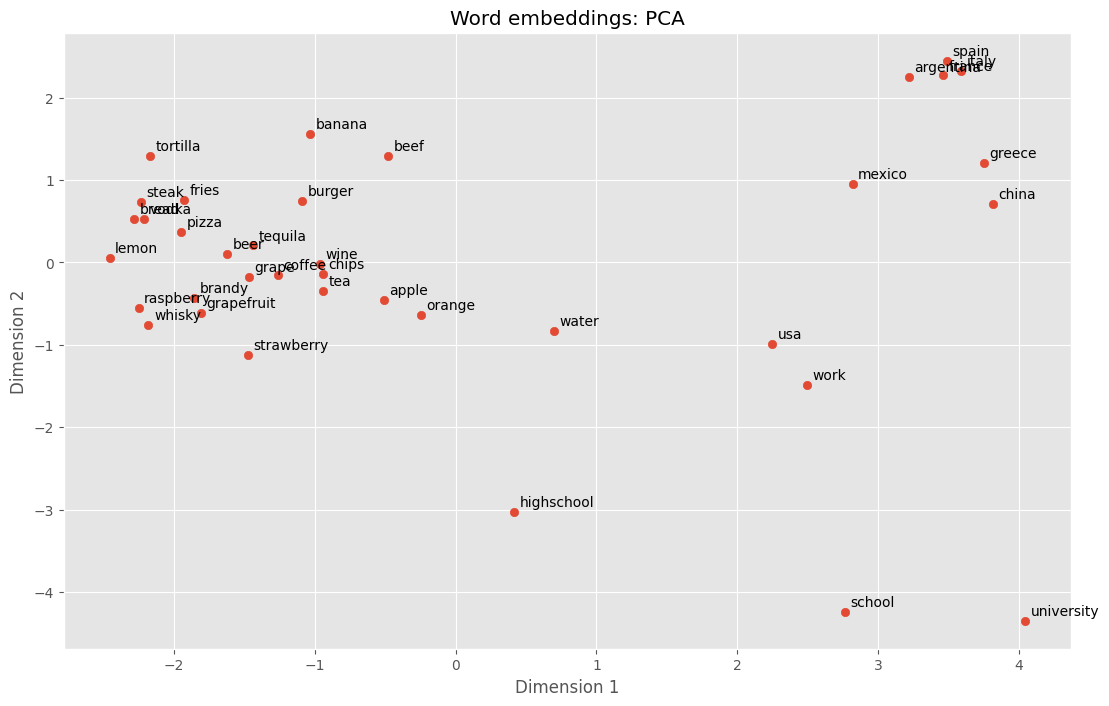

Explained variance: 0.38315594


array([[-1.0925041 ,  0.74372876],
       [-2.1670628 ,  1.292367  ],
       [-2.2834158 ,  0.52902204],
       [-1.9500184 ,  0.3721772 ],
       [-0.47766322,  1.2940513 ],
       [-2.2378066 ,  0.7307441 ],
       [-1.92657   ,  0.75569266],
       [-0.9450014 , -0.13504937],
       [ 3.2193754 ,  2.246692  ],
       [ 2.8189163 ,  0.95552075],
       [ 3.488131  ,  2.4482503 ],
       [ 2.2472813 , -0.9943583 ],
       [ 3.4618902 ,  2.269228  ],
       [ 3.5916219 ,  2.3245144 ],
       [ 3.7501671 ,  1.2115402 ],
       [ 3.8158362 ,  0.7147594 ],
       [ 0.69911534, -0.83254534],
       [-1.6239517 ,  0.10265356],
       [-1.439923  ,  0.20648277],
       [-0.962911  , -0.02196907],
       [-2.1817415 , -0.7590347 ],
       [-1.8575069 , -0.43355262],
       [-2.2137516 ,  0.52904844],
       [-1.2642858 , -0.15639098],
       [-0.9421787 , -0.34516948],
       [-0.5101739 , -0.45191413],
       [-1.033432  ,  1.5628412 ],
       [-0.24471143, -0.6360452 ],
       [-2.4575224 ,

In [10]:
plot_embeddings(PATH, words, emb_dim, embeddings_dict, PCA)

Obtuvimos una varianza explicada de 38.32%. Eso significa que, utilizando solo dos componentes principales, logramos representar aproximadamente el 38.32% de la varianza de los 37 embeddings que seleccionamos.

Ahora, conservar solo el 38.32% no es necesariamente malo, ya que de momento el objetivo no es reconstruir los embeddings completos, sino más bien poder explorar visualmente como son algunas de sus relaciones.

Como se puede observar en la gráfica, las palabras se dividen en varios grupos:

- Están los **países** (como `spain`, `italy`, `france`, etc.) ubicados en la región derecha, donde `usa` es el que se encuentra más separado del resto de países, pero sigue en la región dedicada a dicho grupo.

- Hay **alimentos**, los cuales se ubican en zona superior izquierda de la gráfica. Algunos ejemplos son `steak`, `burger`, `pizza`, `bread`, etc. Algo interesante es que beef y burger aparecen algo más separados, de modo que, aún cuando hay una agrupación semántica, no todos los alimentos tienen exactamente la misma representación.

- Tenemos las **bebidas**, ubicadas la zona izquierda y central del gráfico. Tenemos ejemplos como `beer` o `tequila`. Lo curioso es que algunas bebidas están mezcladas con alimentos y frutas.

- Hay **frutas**, como `orange` y `apple`, pero su distribución esta un poco variada, pero eso no es necesariamente contradictorio. Por ejemplo, apple podría ser una fruta o una empresa, y orange podría ser una fruta o un color. Así que, como GloVe usa solamente un embedding estadístico por token, puede incorporar varios contextos en un mismo vector, lo cual podría explicar en parte lo que sucede en el caso de la categoría de frutas. Aunque también hay que tomar en cuenta que, al realizar la reducción de dimensionalidad, se pierde parte de la información de los embeddings originales.

- Por último, está `educación y trabajo`, ubicada a la zona inferior de la gráfica. Tenemos ejemplos como `school`, `university` y `highschool`.

Con respecto a lo que representan las dimensiones de nuestra gráfica, no tenemos información suficiente como para afirmar qué distingue cada uno. EN sí, son combinaciones lineales de la 50 dimensiones originales.

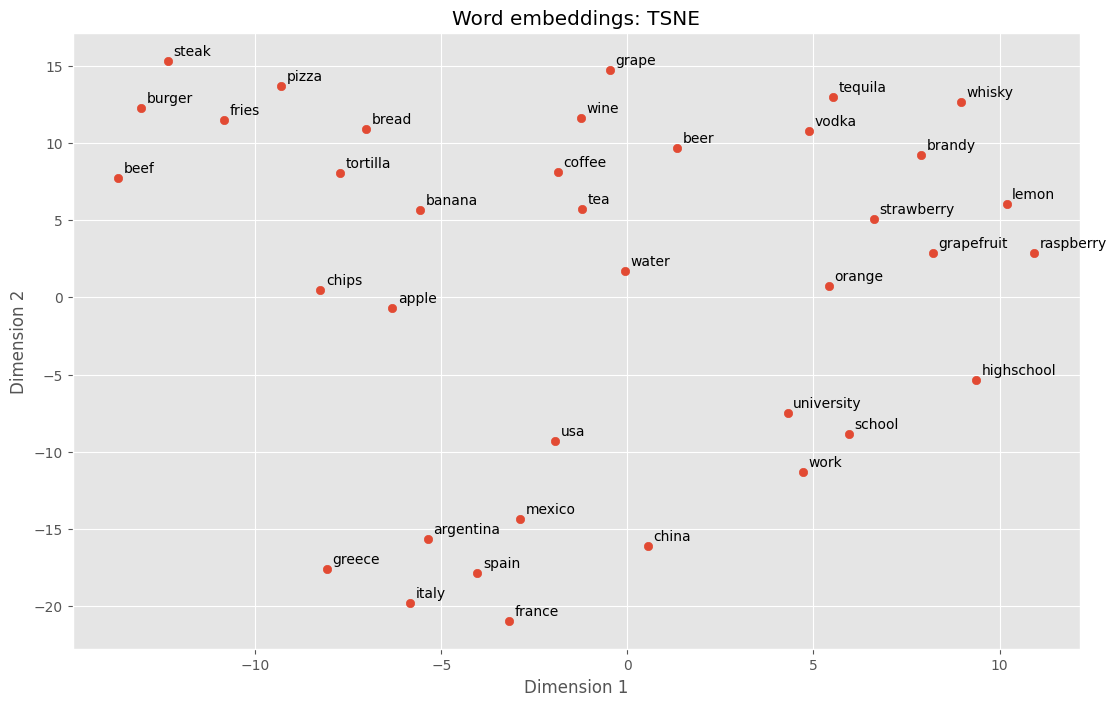

In [11]:
# Reducción de dimensionalidad mediante t-SNE para visualización
embeddings = plot_embeddings(PATH, words, emb_dim, embeddings_dict, TSNE)

La distribución de t-SNE quedó muy diferente a la de PCA. De primeras, pareciera ser que en esta gráfica las categorías quedaron mejor separadas que en PCA. Los alimentos están principalmente en la zona superior izquierda, los países en la parte inferior izquierda, las bebidas en la parte superior central y derecha, y las de educación y trabajo están en la parte inferior derecha.

Aquí tampoco podríamos afrimar con exactitud qué signifia cada dimensión. Pero es importante señalar que, a diferencia de PCA, las coordenadas que obtuvimos mediante t-SNE no son cmbinaciones lineales de las 50 dimensiones originales, sino que realmente se obtienen a través de un proceso de optimización el cual lo que hace es que busca mantener las relaciones de vecindad entre los embeddings.

## 8. Calculemos analogías

Cosine similarity is the dot product divided by the product of vector norms. For an analogy a:b::c:d, search for the vector closest to b − a + c, excluding the three input words.

### 8.1. ¿Qué es la similitud del coseno y cómo funciona?

Entender esto es fundamental para lo que sigue. Lo que hace la similitud del coseno es que mide qué tan similares son dos vectores en base al ángulo que existe entre ellos, independientemente de sus magnitudes.

Posee la siguiente fórmula:

$$\operatorname{sim}(A,B) = \frac{A\cdot B}{\|A\|\|B\|}=\cos(\theta)$$

Donde:
- $A$ es el vector de la primera palabra
- $B$ es el vector de la segunda palabra
- $A\cdot B$ es el producto punto entre los dos vectores
- $||A||$ es la magnitud del primer vector
- $||B||$ es la magnitud del segundo vector
- $\theta$ es el ángulo entre los vectores

Donde el resultado termina en el intervalo: $\operatorname{sim}(A,B)\in[-1,1]
$, de modo que si el resultado es 1, significa que hay 0° y ambas palabras van en la misma dirección; si es 0, significa que hay 90° y que son ortogonales; y si es -1, entonces hay 180° y van en direcciones opuestas.

Igualmente, es importante aclarar por qué se utiliza la similitud del coseno y no la distancia euclidiana, ya que la distancia euclidiana toma en cuenta las posiciones y magnitudes de los vectores, mientras que la similitud del coseno se enfoca más que nada en sus direcciones.

Entonces, una vez calculado el producto punto, las magnitudes y de haber calculado $\operatorname{sim}(A,B)$, obtenemos el ángulo entre ambos vectores al hacer:

$$\theta=\cos^{-1}(\operatorname{sim}(A,B))$$

Con eso claro, construimos nuestro código usando justamente la similitud de coseno la cual utilizaremos tanto para buscar palabras que sean similares como para resolver analogías.

In [12]:
# Ordenamos las palabras según su similitud del coseno
# Definimos la función y sus parámetros de entrada
def cosine_search(vector, embeddings_dict, excluded=(), top_n=10):
    # Construimos la matriz completa,
    # donde primero convertimos un diccionario en una lista
    words = list(embeddings_dict)
    # Construimos una matriz con todos los embeddings
    # A diferencia de PCA y t-SNE, aquí trabajamos con el vocabulario completo
    matrix = np.stack([embeddings_dict[word] for word in words])
    # Calculamos las magnitudes
    denominator = np.linalg.norm(matrix, axis=1) * np.linalg.norm(vector)
    scores = np.full(len(words), -np.inf, dtype=np.float32)
    # Calculamos sim(A,B)
    # Con matrix @ vector se hace el cálculo de los productos punto
    np.divide(matrix @ vector, denominator, out=scores, where=denominator > 0)
    # Para excluir determiandas palabras, por ejemplo,
    # evitar que la palabra se compare consimo misma
    for word in excluded:
        if word in embeddings_dict:
            scores[words.index(word)] = -np.inf
    # Ordenamos los resultados
    indices = np.argsort(-scores)[:max(0, top_n)]
    return [(words[i], float(scores[i])) for i in indices if np.isfinite(scores[i])]

Ya que tenemos nuestra función auxiliar, procedemos a implementar las funciones para encontrar palabras más similares y para hacer analogías.

Una analogía se trata de identificar una relación entre dos elementos y trasladar dicha relación a otros dos elementos. Por ejemplo, la frase "*Man is to king as woman is to ___.*", donde la respuesta esperada sería `queen`.

Podemos expresar una analogía de la siguiente forma:

$$A:B::C:D$$

Que, en palabras más simples, significa que *A es a B como C es a D*. Así que aquí nuestro objetivo es encontrar D a partir de los 3 elementos que ya se conocen.

Para resolver esa relación usando solamente vectores de números reales vamos a plantear un ejemplo para que sea sencillo de explicar. Si suponemos que hay una relación vectorial aproximadamente equivalente entre las palabras `man` y `king`, y entre `woman` y `queen`, entonces podríamos expresar dicha relación de la siguiente forma:

$$\vec{king} - \vec{man} \approx \vec{queen} - \vec{woman}$$

Donde, al despejar D (en este caso `queen`), obtendríamos lo siguiente:

$$\vec{D} \approx \vec{B} - \vec{A} + \vec{C}$$

Dicha resta entre dos vectores se puede interpretar como un desplazamiento del espacio de embeddings. Es decir, tenemos la relación entre `man` y `king`, de modo que esa relación se aplicará posteriormente al vector de `woman`.

In [13]:
# Analogía: palabra1 es a palabra2 como palabra3 es a ?
def analogy(word1, word2, word3, embeddings_dict):
    # Convertimos las tres palabras a minúscula
    # y las guardamos en una tupla
    inputs = tuple(word.lower() for word in (word1, word2, word3))
    # Comprobamos que las 3 existan en el vocabulario
    for word in inputs:
        if word not in embeddings_dict:
            raise ValueError(f'Word not found: {word}')
    # Asignamos las 3 palabras a sus respectivas variables
    a, b, c = inputs
    # Aplicamos la fórmula D = B - A + C
    target = embeddings_dict[b] - embeddings_dict[a] + embeddings_dict[c]
    #  Mandamos a la función auxiliar el vector calculado
    return cosine_search(target, embeddings_dict, inputs, top_n=1)[0]

In [14]:
analogy('man', 'king', 'woman', embeddings_dict)

('queen', 0.8609580397605896)

Entonces, siguiendo con el ejemplo "*Man is to king as woman is to ___.*", tenemos que se obtuvo correctamente el resultado de `queen` con una similitud del coseno de 0.8610.

Para la función de palabras similares hacemos 4 cosas:
- Convertimos las palabras en minúsculas
- Verificamos que la palabra exista dentro del diccionario
- Recuperamos su embedding original de 50 dimensiones
- Buscamos aquellos embeddings que tengan mayor similitud con dicha palabra (sin incluir la palabra consultada).

In [15]:
def find_most_similar(word, embeddings_dict, top_n=10):
    word = word.lower()
    if word not in embeddings_dict:
        raise ValueError(f'Word not found: {word}')
    return cosine_search(embeddings_dict[word], embeddings_dict, (word,), top_n)

En este caso vamos a estar buscando palabras que sean similares a `mexico`.

In [16]:
most_similar = find_most_similar('mexico', embeddings_dict)

In [17]:
for i, (word, score) in enumerate(most_similar, 1):
    print(f'{i} ---> {word}: {score:.4f}')

1 ---> mexican: 0.8551
2 ---> venezuela: 0.8497
3 ---> colombia: 0.8490
4 ---> peru: 0.8446
5 ---> chile: 0.8439
6 ---> puerto: 0.8363
7 ---> rico: 0.8195
8 ---> cuba: 0.8125
9 ---> guatemala: 0.8114
10 ---> panama: 0.8097


Los resultados que obtuvimos tienen bastante coherencia. La palabra `mexican` la más parecida, teniendo una similitud del 0.8551. Y la relación se entiende, ya que una es el nombre del país y otra es el gentilicio.

Luego aparecen países, donde estos comparten con México diferentes relaciones geográficas, históricas, lingüísticas y culturales.

El caso de Puerto Rico fue curioso, ya que se separó en dos tokens: `puerto` y `rico`, en vez de quedar como `puerto rico`. Así que esta sería una limitación de trabajar con embeddings estadíticos a nivel de palabra. Pero igualmente, hay que tomar en consideración que puerto y rico pueden aparecer en otros contextos, por lo que no podemos afirmar que GloVE representa solamente a la entidad geográfica de Puerto Rico.

**Aclaración:** una similitud de 0.8551 no significa que haya un 85.51% de precisión. Más bien ignifica que el coseno del ángulo entre los vectores `mexico` y `mexican` es aproximadamente ese valor. Es decir, la similitud del coseno es una medida geométrica, no una probabilidad ni una métrica de clasificación.

A continuación presentamos otros ejemplos.

En el caso de la analogía con países como france, paris e italy, obtuvimos rome con una similitud del coseno de 0.8379, donde en este caso la relación es entre un país y su capital.

En el caso de coffee, se distinguieron dos conceptos, que fueron la similitud semántica (palabras con significados parecidos) y la relación semántica (palabras asociadas entre sí). Por ejemplo, el café y el té son bebidas con características parecidas, mientras que `coffee` y `drink` representan una relación entre un concepto específico y una categoría más general.

In [18]:
print(analogy('france', 'paris', 'italy', embeddings_dict))
print(find_most_similar('coffee', embeddings_dict, 5))

('rome', 0.8378683924674988)
[('drink', 0.8187440037727356), ('drinks', 0.8176288604736328), ('wine', 0.8141363263130188), ('tea', 0.8079648613929749), ('beer', 0.8042464256286621)]


Siguiendo con las pruebas de analogía, podemos también probar cuáles son las limitaciones de los embeddings al revisar diferentes tipos de relaciones. A continuación, haremos las siguientes pruebas:

| Tipo de analogía |	A |	B |	C |	Respuesta esperada |
| --- | --- | --- | --- | --- |
| Género |	man |	king |	woman |	queen |
| Capitales |	france |	paris |	italy |	rome |
| Plurales |	dog |	dogs |	cat |	cats |
| Tiempos verbales |	walk |	walked |	jump |	jumped |
| Comparativos |	good |	better |	bad |	worse |
| Monedas |	mexico |	peso |	japan |	yen |
| Gentilicios |	mexico |	mexican |	canada |	canadian |
| Profesiones y lugares |	doctor |	hospital |	teacher |	school |
| Antónimos |	hot |	cold |	big |	small |
| Relaciones conceptuales |	bird |	sky |	fish |	water |

Como se podrá observar, hay algunas relaciones con son más obvias y mejor definidas que otras. Por ejemplo, puede que en "profesiones y lugares" o en "relaciones conceptuales" obtengamos varias respuestas que sean igual de razonables.

In [19]:
# Pruebas de analogías adicionales
examples = [
    ('man', 'king', 'woman', 'queen'),
    ('france', 'paris', 'italy', 'rome'),
    ('dog', 'dogs', 'cat', 'cats'),
    ('walk', 'walked', 'jump', 'jumped'),
    ('good', 'better', 'bad', 'worse'),
    ('mexico', 'peso', 'japan', 'yen'),
    ('mexico', 'mexican', 'canada', 'canadian'),
    ('doctor', 'hospital', 'teacher', 'school'),
    ('hot', 'cold', 'big', 'small'),
    ('bird', 'sky', 'fish', 'water')
]

correct = 0

for a, b, c, expected in examples:

    # Resolvemos la analogía
    predicted, score = analogy(
        a, b, c, embeddings_dict
    )

    # Comparamos las palabras esperadas y las predichas.
    is_correct = predicted == expected

    if is_correct:
        correct += 1

    print(f'{a} : {b} :: {c} : ?')
    print(f'Expected: {expected}')
    print(f'Predicted: {predicted}')
    print(f'Similarity: {score:.4f}')
    print(f'Match: {is_correct}')
    print('-' * 40)

print(f'Correct analogies: {correct}/{len(examples)}')
print(f'Exact match rate: {correct / len(examples):.2%}')

man : king :: woman : ?
Expected: queen
Predicted: queen
Similarity: 0.8610
Match: True
----------------------------------------
france : paris :: italy : ?
Expected: rome
Predicted: rome
Similarity: 0.8379
Match: True
----------------------------------------
dog : dogs :: cat : ?
Expected: cats
Predicted: cats
Similarity: 0.8995
Match: True
----------------------------------------
walk : walked :: jump : ?
Expected: jumped
Predicted: jumped
Similarity: 0.8030
Match: True
----------------------------------------
good : better :: bad : ?
Expected: worse
Predicted: worse
Similarity: 0.8973
Match: True
----------------------------------------
mexico : peso :: japan : ?
Expected: yen
Predicted: currency
Similarity: 0.7815
Match: False
----------------------------------------
mexico : mexican :: canada : ?
Expected: canadian
Predicted: canadian
Similarity: 0.9228
Match: True
----------------------------------------
doctor : hospital :: teacher : ?
Expected: school
Predicted: school
Similari

Tenemos que de las 10 analogías que probamos, solo 7 fueron correctas. Aquí lo importante no sería la tasa de coincidencia, sino más bien el tipo de relaciones que GloVe logró recuperar y cuáles no.

GloVe pudo recuperar aquellas relaciones sintácticas o morfológicas como pasar de singular a plural, de presente a pasado, de adjetivo a comparativo o de país a gentilicio.

Con respecto a aquellas que tuvo incorrectas, podemos empezar con la de dinero, donde esperábamos obtener `yen` de resultado y en vez de eso obtuvimos `currency`. Aunque la respuesta no fue la esperada, su respuesta no está del todo desvinculadas, puede currency significa moneda o divisa, de modo que el yen pertenece a dicha categoría. Así que puede que la operación vectorial sí detectara la relación monetaria, pero no con la suficiente especificidad como para darse cuenta que esperábamos el tipo de moneda de Japón.

Sobre los antónimos, esperábamos `small` y obtuvimos `much`. Ahora, es importante aclarar que ser antónimos no significa necesariamente que los embeddings de dichas palabras apunten a direcciones opuestas. Por ejemplo, `hot` y `cold` se usan para contextos prácticamente idénticos, y debido a que GloVe aprende a partir de estadísticas de coocurrencia, entonces puede que haya generado representaciones que fueran relativamente similares para esas palabras. Eso sin contar que intentamos pasar la posición relacionada con la temperatura a otra relacionada con el tamaño. Así que ahí tenemos una importante limitación, que es que no siempre las relaciones lingüísticas puede ser representadas a través de operaciones vectoriales lineales.

Finalmente, sobre relaciones conceptuales esperábamos `water` y obtuvimos `hot`. La relación era de un animal y el medio por el cual se desplaza. Mientras que para nosotros fue una relación intuitiva, para las operaciones vectoriales no lo fue. Recordemos que las palabras pueden aparecer en muchos contextos,donde cada embedding puede combinar varios contextos dentro de un único vector. Aunque no sabemos porqué la respuesta fue `hot`, lo que sí sabemos es que la operación vectorial no obtuvo la relación que esperábamos que consiguiera.

Otro punto importante a considerar es que tener una similitud alta no significa que tengamos una respuesta correcta. Por ejemplo, en la analogía de los antónimos obtuvimos incorrectamente el resultado de `much` con una similitud de 0.8297, la cual fue mayor que las respuestas correctas como jumped (con 0.8030) y school (con 0.8061). Así que la similitudde conseno nos permite poder encontrar posibles respuestas, pero no nos grantiza que dichas repuestas sean semánticamente correctas.


Entonces, para acabar, realizamos una verificación final de nuestra implementación para revisar 4 condiciones:
- Tamaño del vocabulario: 400,001 entradas
- Dimensionalidad de los embeddings: 50 componentes
- Cantidad de palabras similares: 10 resultados
- Exclusión de la palabra consultada (en este caso que `mexico` no aparezca entre los resultados)

In [20]:
assert len(embeddings_dict) in (400000, 400001)
assert embeddings_dict['king'].shape == (50,)
assert len(most_similar) == 10
assert all(word != 'mexico' for word, score in most_similar)
print('Basic checks passed')

Basic checks passed


Entonces tenemos que todas las verificaciones se pasaron, lo cual significa que nuestra implementación se realizó tal y como esperamos.

## 9. Reflexiones finales

Con esta actividad pudimos aprender cómo se puede representar el lenguaje humano en una estructura matemática a través de vectores. Mediante los embeddings previamente entrenados de GloVe, pudimos trabajar con un vocabulario de 400,001 tokens, donde cada uno fue representados por un vector de 50 dimensiones. Eso nos permitió ver cómo las relaciones entre palabras pueden aprenderse a partir de patrones estadísticos que se encuentran presentes en grandes cantidades de texto, sin tener que definir de forma manual el significado de cada palabra.

Al empezar con los métodos de reducción de dimensionalidad PCA y t-SNE para visualizar las relaciones entre los diferentes grupos de palabras, aprendimos que, aunque dichos métodos nos facilitan entender las relaciones entre palabras, también presentan limitaciones, pues no conservan completamente la estructura del espacio vectorial original. Por ejemplo, mediante PCA logramos conservar aproximadamente el 38.32% de la varianza de los embeddings seleccionados, mientras que t-SNE nos permitió observar una mayor separación visual entre algunas categorías de palabras.

Luego, al implementar la similitud del coseno, pudimos comparar directamente los embeddings de 50 dimensiones e indentificar palabras que estaban relacionadas. Lo que más podríamos destacar es que las palabras con mayor similitud no eran necesariamente sinónimos, sino que también podían compartir contextos lingüísticos, características o relaciones conceptuales.

Así que con la similitud del coseno pudimos tanto encontrar palabras parecidas como resolver problemas de analogía, pero igualmente hubo algunos casos de ejercicio de analogía donde los resultados no fueron los esperados. De las 10 analogías que probamos, 7 fueron correctas, de modo que obtuvimos una tasa de coincidencia del 70% dentro de nuestra muestra.

De eso, aprendimos que tener una similitud del coseno elevada no garantiza que la respuesta vaya a ser necesariamente correcta, y que hay relaciones lingüísticas tan complejas que no siempre se pueden representar mediante operaciones vectoriales lineales. Igualmente, aprendimos que los embeddings estáticos también pueden tener problemas para diferenciar entre los distintos significados que puede tener una misma palabra según su contexto.

En conclusión, aunque los embeddings no poseen una comprensión total del lenguaje humano, aprendimos que son una herramienta fundamental para poder representar y procesar información que venga en lenguaje humano de una manera computacional. También aprendimos que las relaciones que estos embeddings pueden representar dependen de los contextos en los que aparecen las palabras durante el entrenamiento, así como de los distintos significados que dichas palabras pueden llegar a tener.


## 10. Referencias Bibliográficas

- Jeffrey Pennington, Richard Socher, Christopher Manning (2014). "GloVe: Global Vectors for Word Representation". Recuperado de: https://aclanthology.org/D14-1162/?utm_source=chatgpt.com

- Cole Stryker y Jim Holdsworth (2024). "¿Qué es el procesamiento de lenguaje natural (PLN)?". Recuperado de: https://www.ibm.com/mx-es/think/topics/natural-language-processing

- Amazon Web Services (S.F.). "¿Qué es el procesamiento de lenguaje natural (NLP)?". Recuperado de: https://aws.amazon.com/es/what-is/nlp/

- Joel Bernard (2023). "¿Qué son las incrustaciones de palabras?". Recuperado de: https://www.ibm.com/mx-es/think/topics/word-embeddings

- zilliz (2024). "GloVe". Recuperado de: https://zilliz.com/es/glossary/glove

- Moraneus (2024). "Python Serialization 101: Unlock the Essentials for Your Projects". Recuperado de: https://medium.com/@moraneus/python-serialization-101-unlock-the-essentials-for-your-projects-5dd8b5bbbcc5

- Fernán García de Zúñiga (2025). "Python Pickle: qué es y por qué utlizar esta serialización". Recuperado de: https://www.arsys.es/blog/python-pickle-que-es-y-por-que-utlizar-esta-serializacion

- geeksforgeeks (2025). "Diferencia entre PCA y t-SNE". Recuperado de: https://www.geeksforgeeks.org/machine-learning/difference-between-pca-vs-t-sne/

- Shittu Olumide (2026). "Cómo elegir entre PCA y t-SNE para la visualización". Recuperado de: https://machinelearningmastery.com/choosing-between-pca-and-t-sne-for-visualization/